In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Add the parent directory to Python path so we can import from src
import sys
import os
parent_dir = os.path.dirname(os.getcwd())
sys.path.append(parent_dir)

from src.tree_bstats.balance_index_coefficients import BalanceIndexCoefficients
from src.tree_bstats.clade_basis import clade_mean, clade_cov_matrix
from src.tree_bstats.daughter_basis import daughter_mean, daughter_cov_matrix
from src.tree_bstats.tree import Tree
from src.tree_bstats.unlabelled_tree import UnlabelledTree
from src.tree_bstats.plotting_params import plot_params

# Main text figures

# Figure 2: mean of 17 balance indices represented by the daughter-number basis

In [7]:
mean = []
min_n = 4
max_n = 100
indices = BalanceIndexCoefficients().get_daughter_labels()

# For all n in the range, we will compute the mean of all basis indices under daughter basis
N = range(min_n, max_n + 1)
for n in N:
    mu = daughter_mean(n)
    daughter_coef = BalanceIndexCoefficients(n).get_daughter_coefficients()
    matrix_of_coef= np.array(list(daughter_coef.values()))

    mean.append(np.dot(matrix_of_coef, mu))

mean = np.array(mean)

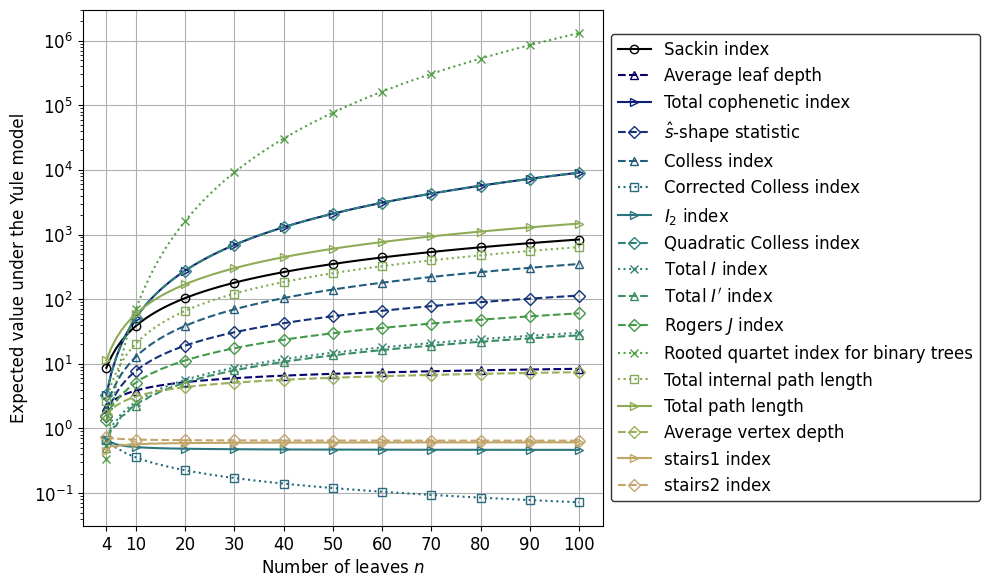

In [ ]:
# Plot the means on a semilogy scale
marker_x = np.array([4, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100])
plt.figure(figsize=(10, 6))
for i, index in enumerate(indices):
    params = plot_params(index)
    plt.semilogy(N, mean[:, i], label=params['label'], 
                 linestyle = params['linestyle'], 
                 marker = params['marker'], markevery=marker_x - min_n, mfc='none',
                 color = params['color'])

plt.xlabel('Number of leaves $n$', fontsize=12)
plt.ylabel('Expected value under the Yule model', fontsize=12)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize = 12, edgecolor = 'black')
# Fontsize for the x and y axes
plt.xticks(marker_x, fontsize=12)
plt.yticks(fontsize=12)
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(parent_dir, 'plots', 'meanPlot.png'), dpi=300, bbox_inches='tight')
plt.show()

# Figure 3: variance of 17 balance indices represented by the daughter-number basis

In [9]:
# This block may take a while (~1-2 minute on my machines)
variances = []
min_n = 4
max_n = 100
indices = BalanceIndexCoefficients().get_daughter_labels()

# For all n in the range, we will compute the variances of all basis indices under daughter basis
N = range(min_n, max_n + 1)
for n in N:
    # Daughter-number coefficients
    daughter_coef = BalanceIndexCoefficients(n).get_daughter_coefficients()
    matrix_of_coef= np.array(list(daughter_coef.values()))

    # Covariance matrix of basis
    daughter_cov = daughter_cov_matrix(n)

    # Calculate the outer product to find all covariances
    cov_matrix = matrix_of_coef @ daughter_cov @ matrix_of_coef.T
    variances.append(np.diag(cov_matrix))
    

variances = np.array(variances)

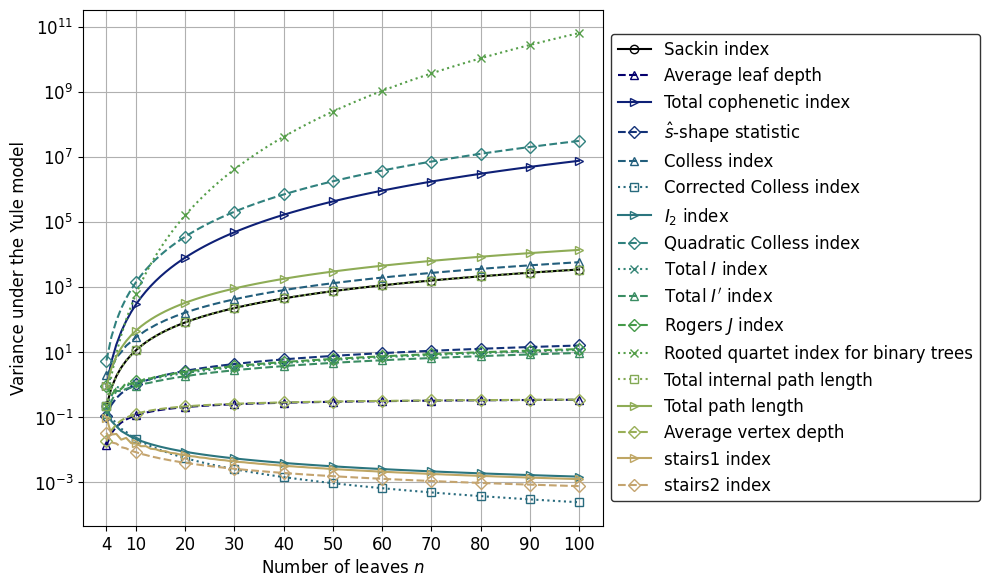

In [10]:
# Plot the variances on a semilogy scale
marker_x = np.array([4, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100])
plt.figure(figsize=(10, 6))
for i, index in enumerate(indices):
    params = plot_params(index)
    plt.semilogy(N, variances[:, i], label=params['label'], 
                 linestyle = params['linestyle'], 
                 marker = params['marker'], markevery=marker_x - min_n, mfc='none',
                 color = params['color'])

plt.xlabel('Number of leaves $n$', fontsize=12)
plt.ylabel('Variance under the Yule model', fontsize=12)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize = 12, edgecolor='black')
# Fontsize for the x and y axes
plt.xticks(marker_x, fontsize=12)
plt.yticks(fontsize=12)
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(parent_dir, 'plots', 'variancePlot.png'), dpi=300, bbox_inches='tight')
plt.show()

# Plot (not used currently): Coefficient of variation for all indices

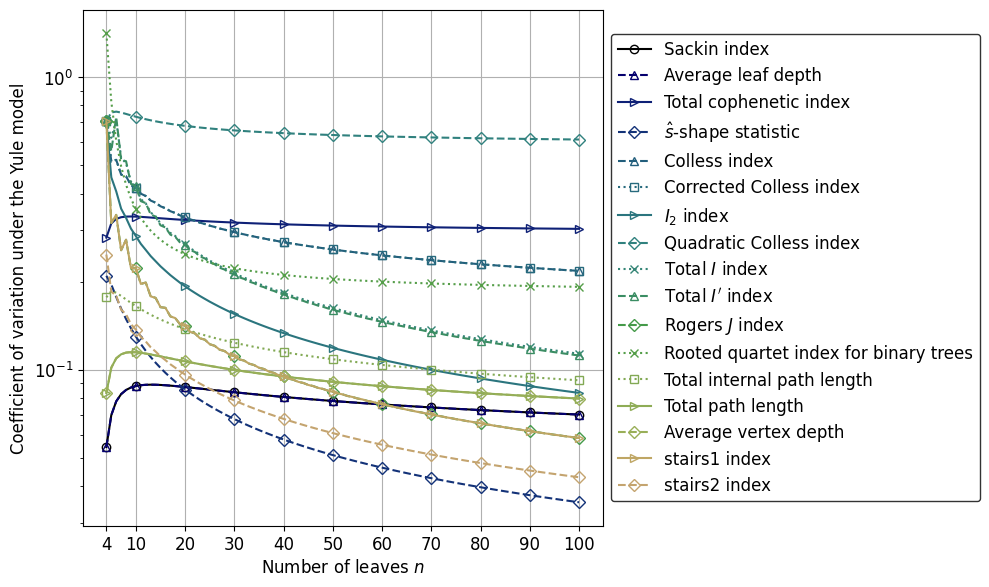

In [11]:
# Plot the coefficient of variation (CV = std / mean) on a semilogy scale
marker_x = np.array([4, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100])
plt.figure(figsize=(10, 6))
for i, index in enumerate(indices):
    params = plot_params(index)
    plt.semilogy(N, np.sqrt(variances[:, i]) / mean[:, i], label=params['label'], 
                 linestyle = params['linestyle'], 
                 marker = params['marker'], markevery=marker_x - min_n, mfc='none',
                 color = params['color'])

plt.xlabel('Number of leaves $n$', fontsize=12)
plt.ylabel('Coefficient of variation under the Yule model', fontsize=12)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize = 12, edgecolor='black')
# Fontsize for the x and y axes
plt.xticks(marker_x, fontsize=12)
plt.yticks(fontsize=12)
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(parent_dir, 'plots', 'coefficient_of_variation_Plot.png'), dpi=300, bbox_inches='tight')
plt.show()

# Plot 4a: correlation matrix

In [28]:
n = 100

# Daughter-number coefficients
indices = BalanceIndexCoefficients().get_daughter_labels()
daughter_coef = BalanceIndexCoefficients(n).get_daughter_coefficients()
matrix_of_coef= np.array(list(daughter_coef.values()))

# Covariance matrix of basis
daughter_cov = daughter_cov_matrix(n)

# Calculate the outer product to find all covariances
cov_matrix = matrix_of_coef @ daughter_cov @ matrix_of_coef.T

# Use cov_matrix_basis to get the correlation matrix
corr_matrix = cov_matrix/ np.sqrt(np.outer(np.diag(cov_matrix), np.diag(cov_matrix)))

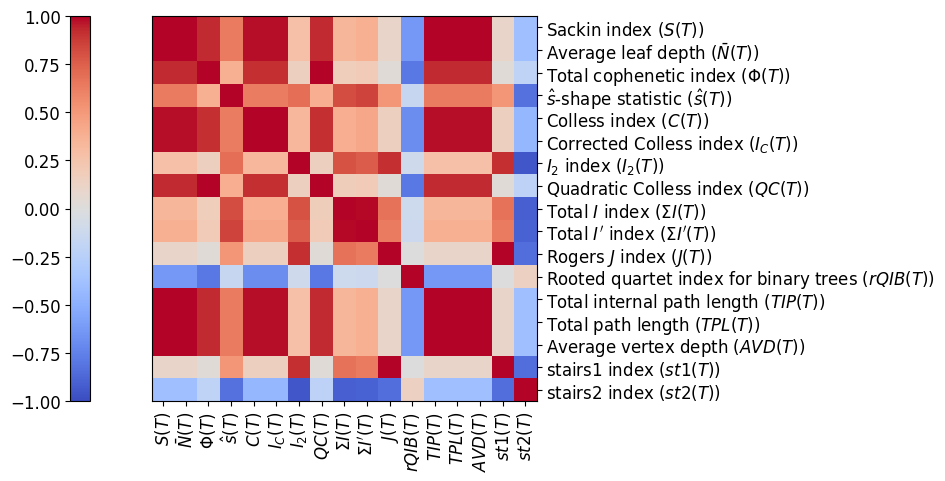

In [32]:
# Plot the correlation matrix
plt.figure(figsize=(8, 5))
plt.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
# Make ticks of the colorbar fontsize 12
plt.colorbar(location='left').ax.tick_params(labelsize=12)

# For this plot, make the labels equal to the formulas rather than names
plotting_labels = [plot_params(index)['formula'] for index in indices]
full_labels = []
for index in indices:
    full_labels.append(index + ' (' + plot_params(index)['formula'] + ')')

abbreviated_labels = [
    'Sackin',
    'Avg Leaf Depth',
    'Total cophenetic',
    '$\\hat{s}$-shape'
]

plt.xticks(ticks=np.arange(len(indices)), labels=plotting_labels, rotation=90, fontsize=12)
plt.yticks(ticks=np.arange(len(indices)), labels=full_labels, fontsize=12)
# Move yticks and labels to right side
plt.gca().yaxis.tick_right()
plt.gca().yaxis.set_label_position('right')

# plt.title('Correlation matrix of balance indices (daughter basis), n = ' + str(n))
# plt.tight_layout()
plt.savefig(os.path.join(parent_dir, 'plots', 'correlation_matrix_daughter_basis_n100.png'), bbox_inches='tight', dpi=300)
plt.show()

# Plot 4b: MDS of the correlation matrix

In [22]:
from sklearn.manifold import MDS
from sklearn.metrics import pairwise_distances

# Use MDS to cluster indices based on correlation matrix
indices = BalanceIndexCoefficients().get_daughter_labels()
# Convert the correlation matrix into a distance matrix
dist_squared = 2 * (1 - corr_matrix) 
zeroes_dist_squared = np.where(np.abs(dist_squared) < 1e-14, 0, dist_squared)
distance_matrix = np.sqrt(zeroes_dist_squared)

# Calculate the mds
mds = MDS(n_components=2, metric='precomputed', init = 'classical_mds')
coords = mds.fit_transform(distance_matrix)

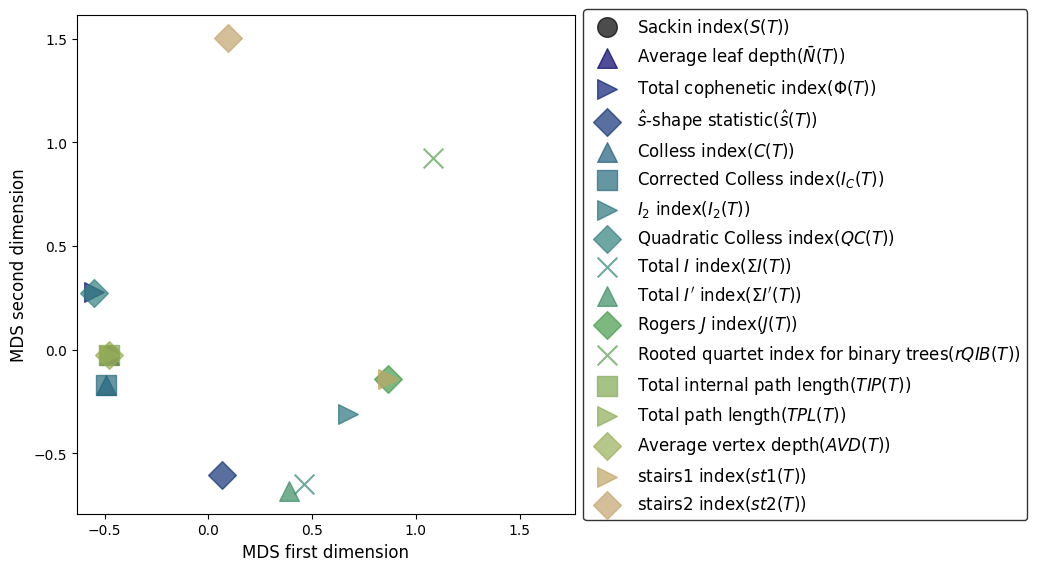

In [23]:
# Now plot the points
plt.figure(figsize=(10,6))

# Full labels (name and formula)
full_labels = []
for index in indices:
    full_labels.append(index + '(' + plot_params(index)['formula'] + ')')

for i in range(len(coords)):
    params = plot_params(indices[i])
    plt.scatter(coords[i, 0], coords[i, 1], label = full_labels[i], 
                color = params['color'], alpha = 0.7,
                marker = params['marker'],
                s = 200)
plt.xlabel("MDS first dimension", fontsize=12)
plt.ylabel("MDS second dimension", fontsize=12)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize = 12, edgecolor='black')
plt.axis('square')
plt.tight_layout()

# plt.savefig(os.path.join(parent_dir, 'plots', 'MDS_plot_corr_matrix.png'))
plt.show()

In [24]:
indices = BalanceIndexCoefficients().get_daughter_labels()
coords = mds.fit_transform(distance_matrix)

# Because some of the indices overlap, we are going to merge them so only one MDS plot appears
sackin_like = ['Sackin index', 
               'Average leaf depth', 
               'Total internal path length', 
               'Total path length', 
               'Average vertex depth']
colless_like = ['Colless index',
                'Corrected Colless index']
j_like = ['Rogers $J$ index',
          'stairs1 index']

clusters = [sackin_like, colless_like, j_like]

# Remove the duplicate entries from our indices and our coords arrays
# Change the name of the representative using this dictionary
for cluster in clusters:
    for j in range(1, len(cluster)):
        i = indices.index(cluster[j])
        indices.remove(cluster[j])
        coords = np.delete(coords, i, axis=0)
    indices[indices.index(cluster[0])] += " cluster" 

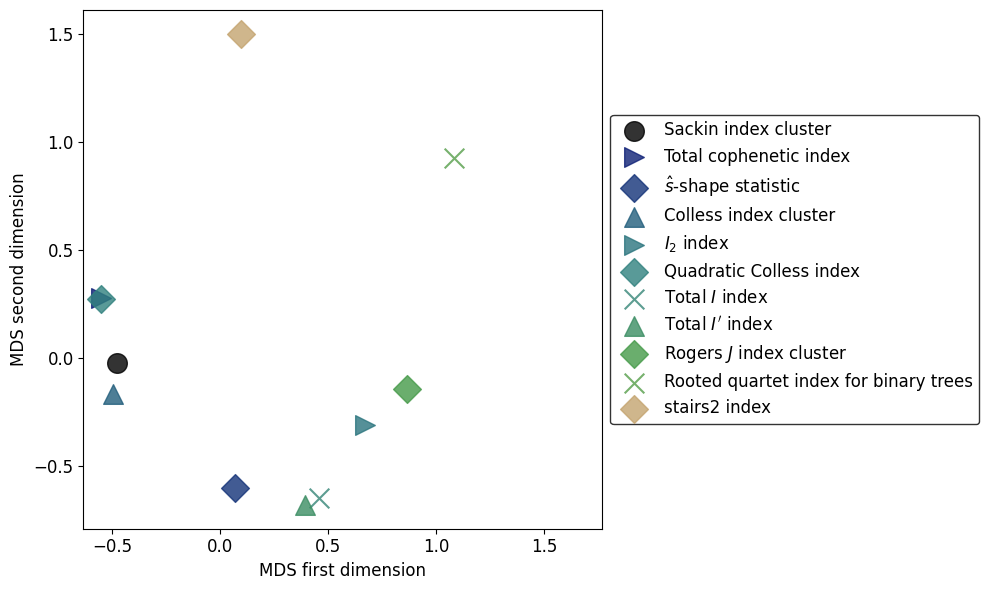

In [25]:
# Make a plot where we do not duplicate cluster entries
plt.figure(figsize=(10,6))

for i in range(len(coords)):
    index = indices[i]
    if index[-7:] == 'cluster':
        params = plot_params(index[:-8])
    else:
        params = plot_params(index)
    plt.scatter(coords[i, 0], coords[i, 1], label = indices[i], 
                color = params['color'], alpha = 0.8,
                marker = params['marker'],
                s = 200)

# Add text for cluster


plt.xlabel("MDS first dimension", fontsize=12)
plt.ylabel("MDS second dimension", fontsize=12)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize = 12, edgecolor='black')
plt.axis('square')
plt.tight_layout()

plt.savefig(os.path.join(parent_dir, 'plots', 'MDS_plot_corr_matrix_with_clusters.png'), bbox_inches='tight', dpi=300)
plt.show()

# Appendix figures

In [ ]:
import scipy.linalg as la
import src.tree_bstats.indices as indices
import pandas as pd

# Figure C1: Errors when projecting indices onto daughter-number basis

In [ ]:
# Pick list of indices to study (all not represented by clade-number basis, and exclude Colijn-Plazzotta)
all_indices = Tree().get_balance_names()
my_indices = Tree().get_balance_names()
# First, we remove the indices that are represented by the clade-number basis
clade_labels = BalanceIndexCoefficients().get_clade_labels()
exclude = clade_labels + ['Colijn-Plazzotta rank']
for label in exclude:
    my_indices.remove(label)

In [ ]:
# Next, for all k=6,...,16, we use least squares to find approximate solution and track residual error for each index

k0 = 6
n = 16
trees = UnlabelledTree(n)

clade_residuals = np.zeros((n-k0 + 1, len(my_indices)))
clade_regression_results = {name: [] for name in my_indices}

for k in range(k0, n+1):

    clade_numbers, _, balance_indices, weights = trees.get_data(k)

    clade_numbers = np.array(clade_numbers)

    
    # clade_numbers = clade_numbers[:, :-1] # uncomment to remove the last column of the clade_numbers (since this is redundant and always equal to 1)
    balance_indices = pd.DataFrame(balance_indices, columns=all_indices)
    # drop Colijn-Plazzatto index along with all columns that are represented by the clade-number basis
    balance_indices = balance_indices.drop(columns=exclude)
    weights = np.array(weights)

    # weight the data by weights before performing least squares
    W = np.sqrt(np.diag(weights))
    Bw = np.dot(W, balance_indices.values)
    Cw = np.dot(W, clade_numbers)

    for i in range(len(my_indices)):
        # Project each balance index onto the clade number axis
        X = la.lstsq(Cw, Bw[:, i])[0]
        clade_regression_results[my_indices[i]].append(X)
        B_proj = np.dot(Cw, X)
        residual = np.sum((B_proj - Bw[:, i])**2)

        # To compare residuals across indices, we divide by the magnitude of the balance index
        residual /= la.norm(Bw[:, i])
        clade_residuals[k-k0, i] = residual


Trees generated with counts  [1, 1, 1, 2, 3, 6, 11, 23, 46, 98, 207, 451, 983, 2179, 4850, 10905]


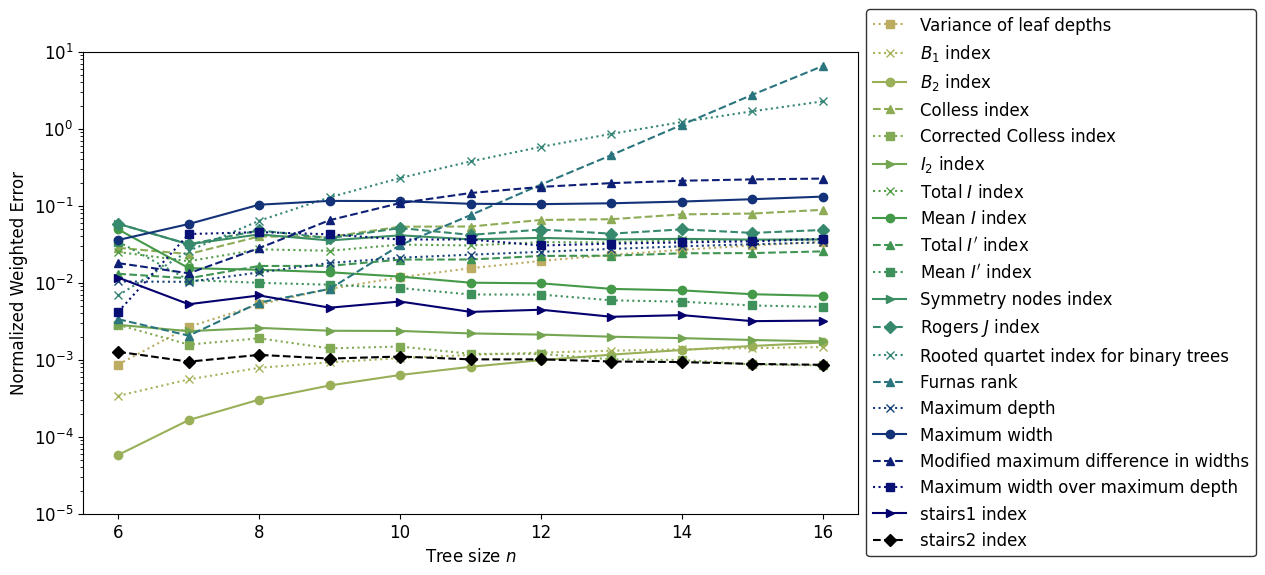

In [ ]:
# Plot these residual curves
# Now plot the residuals

plt.figure(figsize=(10, 6))
for i in range(len(my_indices)):
    params = plot_params(my_indices[i])
    plt.semilogy(range(k0, n+1), clade_residuals[:, i], label=params['label'], 
                 linestyle = params['linestyle'], 
                 marker = params['marker'],
                 color = params['color'])
plt.xlabel('Tree size $n$', fontsize = 12)
plt.ylabel('Normalized Weighted Error', fontsize = 12)
plt.ylim(1e-5, 1e1)
# Move legend to far right
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize = 12, frameon=True, edgecolor = 'black')
plt.xticks(fontsize = 12)
plt.yticks(fontsize = 12)
# plt.title('Error in the best approximation of statistics by the clade-number basis', fontsize = 20)
plt.savefig(os.path.join(parent_dir, 'plots', 'clade_basis_projection_residuals.png'), bbox_inches='tight', dpi=300)
plt.show()

# Figure C2: Errors when projecting balance indices onto the daughter-number basis

In [ ]:
# Pick list of indices to study (all not represented by daughter-number basis, and exclude Colijn-Plazzotta)
all_indices = Tree().get_balance_names()
my_indices = Tree().get_balance_names()
# First, we remove the indices that are represented by the daughter-number basis
daughter_labels = BalanceIndexCoefficients().get_daughter_labels()
exclude = daughter_labels + ['Colijn-Plazzotta rank']
for label in exclude:
    my_indices.remove(label)

In [ ]:
# Next, for all k=6,...,16, we use least squares to find approximate solution and track residual error for each index

k0 = 6
n = 16
trees = UnlabelledTree(n)

daughter_residuals = np.zeros((n-k0 + 1, len(my_indices)))
daughter_regression_results = {name: [] for name in my_indices}

for k in range(k0, n+1):

    _, daughter_numbers, balance_indices, weights = trees.get_data(k)

    daughter_numbers = np.array(daughter_numbers)

    
    # daughter_numbers = daughter_numbers[:, :-1] # uncomment to remove the last column of the daughter_numbers (since this is redundant and always equal to 1)
    balance_indices = pd.DataFrame(balance_indices, columns=all_indices)
    # drop Colijn-Plazzatto index along with all columns that are represented by the daughter-number basis
    balance_indices = balance_indices.drop(columns=exclude)
    weights = np.array(weights)

    # weight the data by weights before performing least squares
    W = np.sqrt(np.diag(weights))
    Bw = np.dot(W, balance_indices.values)
    Dw = np.dot(W, daughter_numbers)

    for i in range(len(my_indices)):
        # Project each balance index onto the daughter number axis
        X = la.lstsq(Dw, Bw[:, i])[0]
        daughter_regression_results[my_indices[i]].append(X)
        B_proj = np.dot(Dw, X)
        residual = np.sum((B_proj - Bw[:, i])**2)

        # To compare residuals across indices, we divide by the magnitude of the balance index
        residual /= la.norm(Bw[:, i])
        daughter_residuals[k-k0, i] = residual


Trees generated with counts  [1, 1, 1, 2, 3, 6, 11, 23, 46, 98, 207, 451, 983, 2179, 4850, 10905]


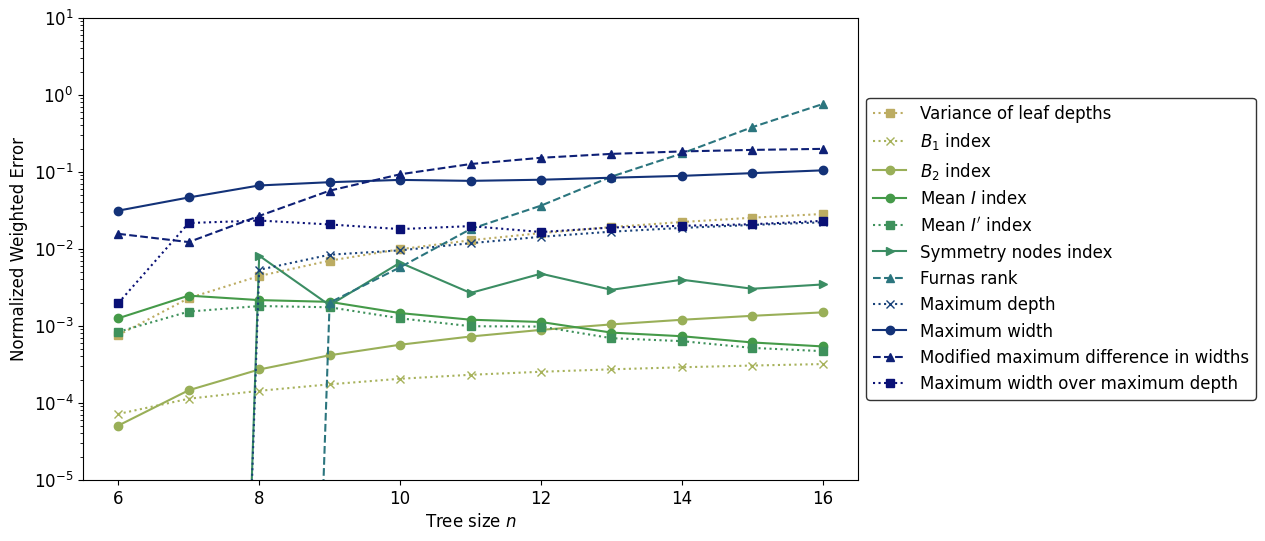

In [ ]:
plt.figure(figsize=(10, 6))
for i in range(len(my_indices)):
    params = plot_params(my_indices[i])
    plt.semilogy(range(k0, n+1), daughter_residuals[:, i], label=params['label'], 
                 linestyle = params['linestyle'], 
                 marker = params['marker'],
                 color = params['color'])
plt.xlabel('Tree size $n$', fontsize = 12)
plt.ylabel('Normalized Weighted Error', fontsize = 12)
plt.ylim(1e-5, 1e1)
# Move legend to far right
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize = 12, frameon=True, edgecolor = 'black')
plt.xticks(fontsize = 12)
plt.yticks(fontsize = 12)
# plt.title('Error in the best approximation of statistics by the daughter-number basis', fontsize = 20)
plt.savefig(os.path.join(parent_dir, 'plots', 'daughter_basis_projection_residuals.png'), bbox_inches='tight', dpi=300)
plt.show()

# Plot C3: Best-fit coefficients for indices not represented by the daughter-number basis

In [ ]:
# Pick list of indices to study (all not represented by clade-number basis, and exclude Colijn-Plazzotta and Furnas ranks)
all_indices = Tree().get_balance_names()
my_indices = Tree().get_balance_names()
# First, we remove the indices that are represented by the clade-number basis
clade_labels = BalanceIndexCoefficients().get_clade_labels()
exclude = clade_labels + ['Colijn-Plazzotta rank', 'Furnas rank']
for label in exclude:
    my_indices.remove(label)

In [ ]:
# Run for all indices
all_indices = Tree().get_balance_names()
my_indices = Tree().get_balance_names()
exclude = ['Colijn-Plazzotta rank']
for label in exclude:
    my_indices.remove(label)

In [ ]:
# Now we project each index onto the clade-number basis for n = 16
n = 16
trees = UnlabelledTree(n)

clade_regression_results = {}

clade_numbers, _, balance_indices, weights = trees.get_data(n)

clade_numbers = np.array(clade_numbers)
clade_numbers = clade_numbers[:, :-1] # uncomment to remove the last column of the clade_numbers (since this is redundant and always equal to 1)
balance_indices = pd.DataFrame(balance_indices, columns=all_indices)
# drop Colijn-Plazzatto index along with all columns that are represented by the clade-number basis
balance_indices = balance_indices.drop(columns=exclude)
weights = np.array(weights)

# weight the data by weights before performing least squares
W = np.sqrt(np.diag(weights))
Bw = np.dot(W, balance_indices.values)
Cw = np.dot(W, clade_numbers)

# Calculate the least squares solution for each index and store the results
for i in range(len(my_indices)):
    X = la.lstsq(Cw, Bw[:, i])[0]
    clade_regression_results[my_indices[i]] = X

Trees generated with counts  [1, 1, 1, 2, 3, 6, 11, 23, 46, 98, 207, 451, 983, 2179, 4850, 10905]


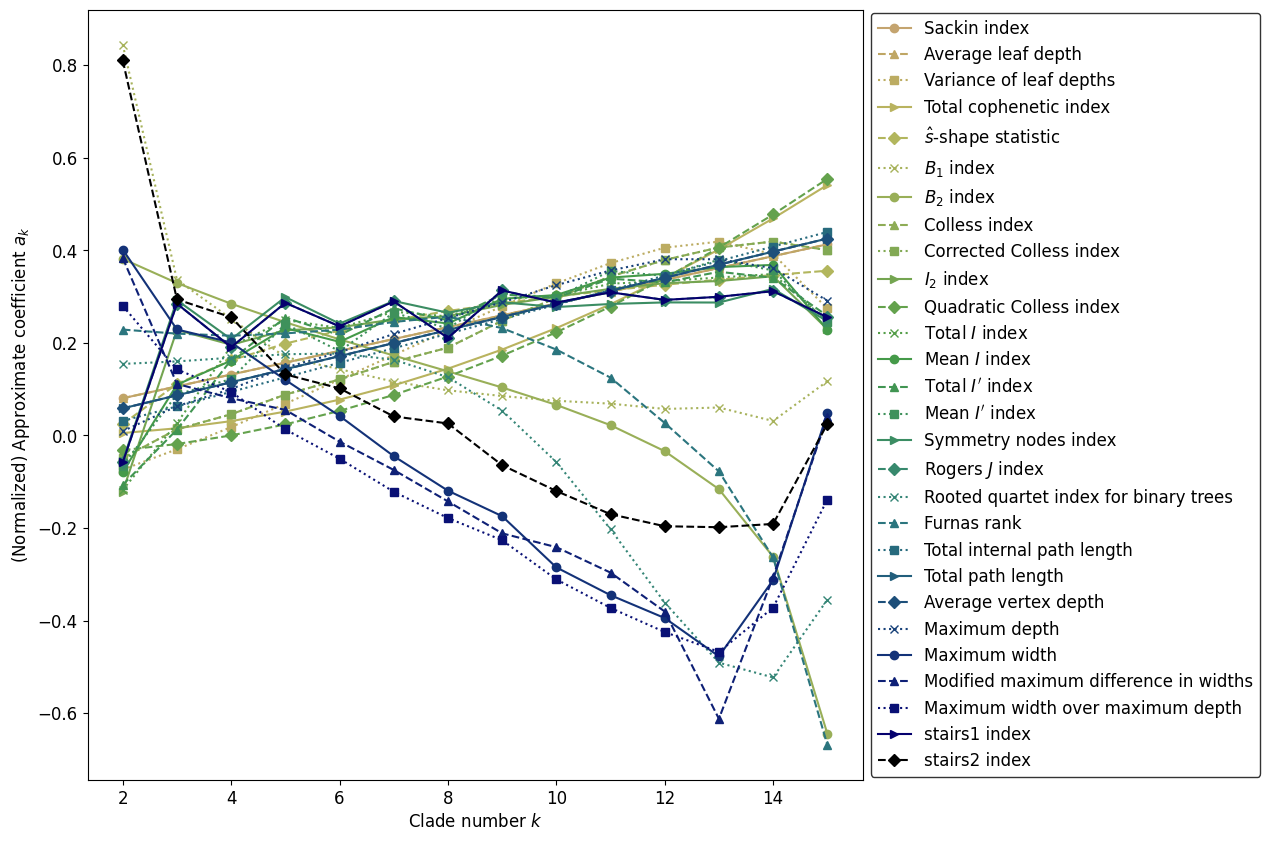

In [ ]:
# Now, plot the coefficients for each index
plt.figure(figsize=(10, 10))

for index in my_indices:
    params = plot_params(index)
    y = clade_regression_results[index].flatten()
    # Normalize the coefficients so has magnitude 1
    y /= np.linalg.norm(y)
    plt.plot(range(2, n), y, label=params['label'], 
             linestyle = params['linestyle'], 
             marker = params['marker'], markevery=1,
             color = params['color'])

plt.xlabel('Clade number $k$', fontsize=12)
plt.ylabel('(Normalized) Approximate coefficient $a_k$', fontsize=12)
plt.xticks(fontsize = 12)
plt.yticks(fontsize = 12)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize = 12, frameon=True, edgecolor = 'black')
# plt.tight_layout()
plt.savefig(os.path.join(parent_dir, 'plots', 'clade_basis_projection_coefficients.png'), bbox_inches='tight', dpi=300)
plt.show()

# 